# 02 — Verified animal-crop cache and training-only quality inspection (V3)
**Wildlife confidence calibration | detected-only inputs | image integrity and preparation handoff**

Run Notebook 01 V3 first. It defines the exact detected-only subset; this notebook prepares the corresponding image cache without changing those scientific decisions. The complete **local V2 image cache** is required. Images are excluded from the GitHub repository, so a repository checkout alone does not supply them.

We independently copy the retained V2 animal crops into the V3 project, verify their recorded SHA-256 hashes and RGB PNG format, and check for exact duplicates across partitions. Copying preserves the existing crop pixels and avoids introducing differences from another decoder, resize implementation or preprocessing run. Separate file copies also prevent later changes in V3 from altering V2 through a hardlink.

Every retained observation must be available and valid before training. Missing or corrupt images are not silently dropped, replaced, downloaded again or converted to full-frame inputs. Preparation can be rerun to verify existing copies and copy remaining files. This notebook does not load V2 trained weights, calculate classifier predictions, fit temperatures or choose thresholds.

**Technical readiness and semantic validity are different.** A correct file hash establishes consistency with the saved input, not that the crop visibly contains the labelled species. The final section provides a deterministic training-only contact sheet and an optional review CSV. No manual quality decisions are fabricated, and viewing or completing the sheet does not silently change the frozen sample.


## 1. Load fixed experiment definitions and integrity helpers

Use the same V3 experiment ID, five categories and partition names as Notebook 01. The hashing, safe-path, atomic-write and freeze helpers support reproducible image copying and dataset handoff. Identifiers are kept as strings. No event or category selection takes place here.


In [1]:
from pathlib import Path
import hashlib, json, shutil
import numpy as np
import pandas as pd

EXPERIMENT_ID = "five_categories_detected_only_v3"
PARENT_EXPERIMENT_ID = "five_categories_camera_balanced_v2"
CLASSES = ['coyote', 'deer', 'fox', 'rabbit', 'skunk']
SPLITS = ['train', 'validation', 'calibration', 'policy', 'test']

def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def jtext(value):
    return json.dumps(value, indent=2, sort_keys=True, ensure_ascii=False, allow_nan=False) + '\n'

def write(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(content, encoding='utf-8')
    temporary.replace(path)

def freeze(path, content):
    path = Path(path)
    if path.exists() and path.read_text(encoding='utf-8') != content:
        raise ValueError(f'Frozen V3 input differs: {path}. Preserve this run; use a new experiment for amendments.')
    if not path.exists():
        write(path, content)

def safe(base, relative):
    base = Path(base).resolve()
    relative = Path(relative)
    if relative.is_absolute() or '..' in relative.parts:
        raise ValueError(f'Unsafe relative path: {relative}')
    path = (base / relative).resolve()
    if not path.is_relative_to(base):
        raise ValueError(f'Path leaves project: {path}')
    return path

def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False)


## 2. Verify the frozen selection and locate the original crop cache

Locate the V3 root automatically or set `PROJECT_ROOT`. The saved `local_source.json` identifies the local V2 root used during Notebook 01; `SOURCE_PROJECT_ROOT` can be set explicitly if that source directory has moved. Source and destination must remain separate.

Verify the V3 protocol and every referenced upstream hash, then load the selected manifest, crop plan and snapshotted V2 ready manifest. Every selected event must have an `animal_crop` plan, with no missing or duplicate image IDs. The V2 snapshot supplies the expected source and cache hashes for the retained inputs.

`verify_png` checks that each processed file exists, has the expected SHA-256 digest, decodes successfully and is a **224 × 224 RGB PNG**. These checks apply to all partitions for technical integrity only. They do not inspect test-classifier performance or revise the data selection.


In [2]:
from PIL import Image
import matplotlib.pyplot as plt
PROJECT_ROOT = None
if PROJECT_ROOT is None:
    candidates = list(dict.fromkeys(p.resolve() for p in [Path.cwd(), Path.cwd() / 'wildlife_confidence_project_v3']
        if (p / 'data/prepared' / EXPERIMENT_ID / 'protocol.json').is_file()))
    if len(candidates) != 1:
        raise FileNotFoundError('Run Notebook 01 V3 first or set PROJECT_ROOT to its V3 root.')
    ROOT = candidates[0]
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
PREPARED = ROOT / 'data/prepared'
EXP = PREPARED / EXPERIMENT_ID
REPORT = ROOT / 'reports' / EXPERIMENT_ID
# Override only if the local V2 project moved after Notebook 01.
SOURCE_PROJECT_ROOT = None
SOURCE_ROOT = (Path(SOURCE_PROJECT_ROOT).expanduser().resolve() if SOURCE_PROJECT_ROOT is not None
    else Path(json.loads((EXP / 'local_source.json').read_text())['source_project_root']).resolve())
if ROOT == SOURCE_ROOT or ROOT.is_relative_to(SOURCE_ROOT) or SOURCE_ROOT.is_relative_to(ROOT):
    raise ValueError('V2 and V3 must be separate, non-nested roots.')
protocol = json.loads((EXP / 'protocol.json').read_text())
if protocol.get('pipeline_kind') != 'megadetector_detected_only_single_v3' or protocol.get('protocol_version') != 3:
    raise ValueError('Expected V3 detected-only protocol.')
for relative, expected in protocol['input_sha256'].items():
    if sha(safe(PREPARED, relative)) != expected:
        raise ValueError(f'Frozen V3 input changed: {relative}')
subset = read_csv(EXP / 'subset_manifest.csv')
plan = read_csv(EXP / 'crop_plan.csv')
reference = read_csv(PREPARED / 'v2_reference/training_ready_manifest.csv').set_index('image_id')
if not plan['mode'].eq('animal_crop').all() or set(plan.image_id) != set(subset.image_id):
    raise ValueError('Fallback or missing crop plan in V3.')
if not subset.image_id.is_unique or not reference.index.is_unique:
    raise ValueError('Duplicate image identities.')
PROTOCOL_SHA, SUBSET_SHA = sha(EXP / 'protocol.json'), sha(EXP / 'subset_manifest.csv')

def verify_png(path, expected):
    if not path.is_file() or sha(path) != expected:
        raise ValueError(f'Missing or changed image: {path}')
    with Image.open(path) as image:
        if image.format != 'PNG' or image.mode != 'RGB' or image.size != (224,224):
            raise ValueError(f'Unexpected crop format: {path}')
        image.load()


## 3. Copy retained crops, check duplicates and establish technical readiness

For each selected V3 event, verify an existing destination file or verify and copy its original V2 crop through a temporary file. A destination is finalized only after the copied bytes pass the same hash and image-format checks. The notebook records verified and failed observations in `image_status.csv`, allowing an incomplete preparation pass to be diagnosed and resumed.

Compare both original-source and processed-cache hashes across partitions. An exact duplicate spanning partitions blocks readiness. This does not detect every near-duplicate or establish independence between camera locations, but it prevents known byte-identical inputs from appearing on both sides of a split.

Technical readiness requires **all selected crops verified**, no cross-partition exact duplicates, and agreement with the frozen selected-manifest row order. The final ready manifest adds source/cache hashes without changing event identity or labels. It is frozen only after the checks pass; `readiness.json` records the actual counts and zero retained full-frame fallbacks.

If readiness fails, inspect the reported file paths and ensure that the source points to the complete local V2 project, including `data/images`. Restore or repair that cache before continuing. Neither a missing image nor a failed integrity check authorizes the notebook to reduce the selected sample.


In [3]:
status = []
for i, row in enumerate(subset.itertuples(index=False), 1):
    expected = reference.loc[row.image_id]
    destination = safe(ROOT, row.cache_relative_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    try:
        if destination.exists():
            verify_png(destination, expected.cache_sha256)
        else:
            source_path = safe(SOURCE_ROOT, expected.cache_relative_path)
            verify_png(source_path, expected.cache_sha256)
            temporary = destination.with_suffix('.png.part')
            try:
                # Independent copy, not a hardlink: V3 writes cannot alter V2 crops.
                shutil.copyfile(source_path, temporary)
                verify_png(temporary, expected.cache_sha256)
                temporary.replace(destination)
            finally:
                temporary.unlink(missing_ok=True)
        status.append({'image_id':row.image_id, 'split':row.split, 'mode':'animal_crop',
            'status':'verified', 'cache_sha256':expected.cache_sha256,
            'source_sha256':expected.source_sha256, 'error':''})
    except Exception as error:
        status.append({'image_id':row.image_id, 'split':row.split, 'mode':'animal_crop',
            'status':'failed', 'cache_sha256':'', 'source_sha256':'', 'error':str(error)})
    if i % 1000 == 0 or i == len(subset):
        print(f'Copied/verified {i}/{len(subset)} crops', flush=True)
image_status = pd.DataFrame(status)
write(REPORT / 'image_status.csv', image_status.to_csv(index=False))
verified = subset.merge(image_status.loc[image_status.status.eq('verified'),
    ['image_id','cache_sha256','source_sha256']], on='image_id', validate='one_to_one')
duplicates = []
for column in ['source_sha256','cache_sha256']:
    repeated = verified.groupby(column).split.nunique()
    part = verified.loc[verified[column].isin(repeated[repeated.gt(1)].index)].copy()
    part['duplicate_check'] = column
    duplicates.append(part)
duplicate_table = pd.concat(duplicates, ignore_index=True)
write(REPORT / 'cross_split_exact_duplicates.csv', duplicate_table.to_csv(index=False))
ready = len(verified) == len(subset) and duplicate_table.empty
readiness = {'protocol_sha256':PROTOCOL_SHA, 'subset_sha256':SUBSET_SHA,
    'planned_images':len(subset), 'verified_images':len(verified),
    'cross_split_duplicate_rows':len(duplicate_table), 'ready_for_final_training':bool(ready),
    'full_frame_fallbacks_retained':0, 'cache_action':'independent_verified_copy_of_V2_animal_crops',
    'manual_crop_verification_performed':False}
write(REPORT / 'readiness.json', jtext(readiness))
if not ready:
    failed = image_status.loc[image_status.status.ne('verified')]
    print(failed[['image_id','error']].head(10).to_string(index=False))
    raise ValueError('V3 images are not ready. Check SOURCE_PROJECT_ROOT points to your complete LOCAL V2 '
        'project including data/images (GitHub excludes that cache), or restore/repair that cache. '
        'No missing image was replaced, downloaded, excluded or converted to a fallback. See image_status.csv.')
if not verified[list(subset.columns)].equals(subset):
    raise ValueError('Ready-manifest identity/order changed.')
freeze(EXP / 'training_ready_manifest.csv', verified.to_csv(index=False))
print('V3 ready for fresh training:', len(verified), 'animal crops; zero full-frame fallbacks.')


Copied/verified 1000/11323 crops
Copied/verified 2000/11323 crops
Copied/verified 3000/11323 crops
Copied/verified 4000/11323 crops
Copied/verified 5000/11323 crops
Copied/verified 6000/11323 crops
Copied/verified 7000/11323 crops
Copied/verified 8000/11323 crops
Copied/verified 9000/11323 crops
Copied/verified 10000/11323 crops
Copied/verified 11000/11323 crops
Copied/verified 11323/11323 crops
V3 ready for fresh training: 11323 animal crops; zero full-frame fallbacks.


## 4. Inspect a reproducible training-only crop-quality sample

Select up to **eight training crops per category** by a deterministic SHA-256 ranking and display them in a contact sheet. Only training images are used: calibration, policy and test images are not displayed for manual tuning. Each image is identified by category and image ID so that observations can be traced to `training_crop_review.csv`.

The optional review fields are `animal_visible`, `crop_matches_label`, `crop_adequate` and `reviewer_notes`. A person must supply these semantic judgments; the notebook leaves them blank and preserves an existing review sheet. High detector confidence, valid geometry and a readable PNG do not automatically answer these questions.

The sheet is descriptive and does not automatically remove observations. Any change to the frozen crop-selection rules or dataset needs an explicitly documented amendment, rather than silent image-by-image adjustments after examining model outcomes. If a manual review is reported in a submission, describe the images actually checked and the recorded findings; do not treat a sample as verification of every input.


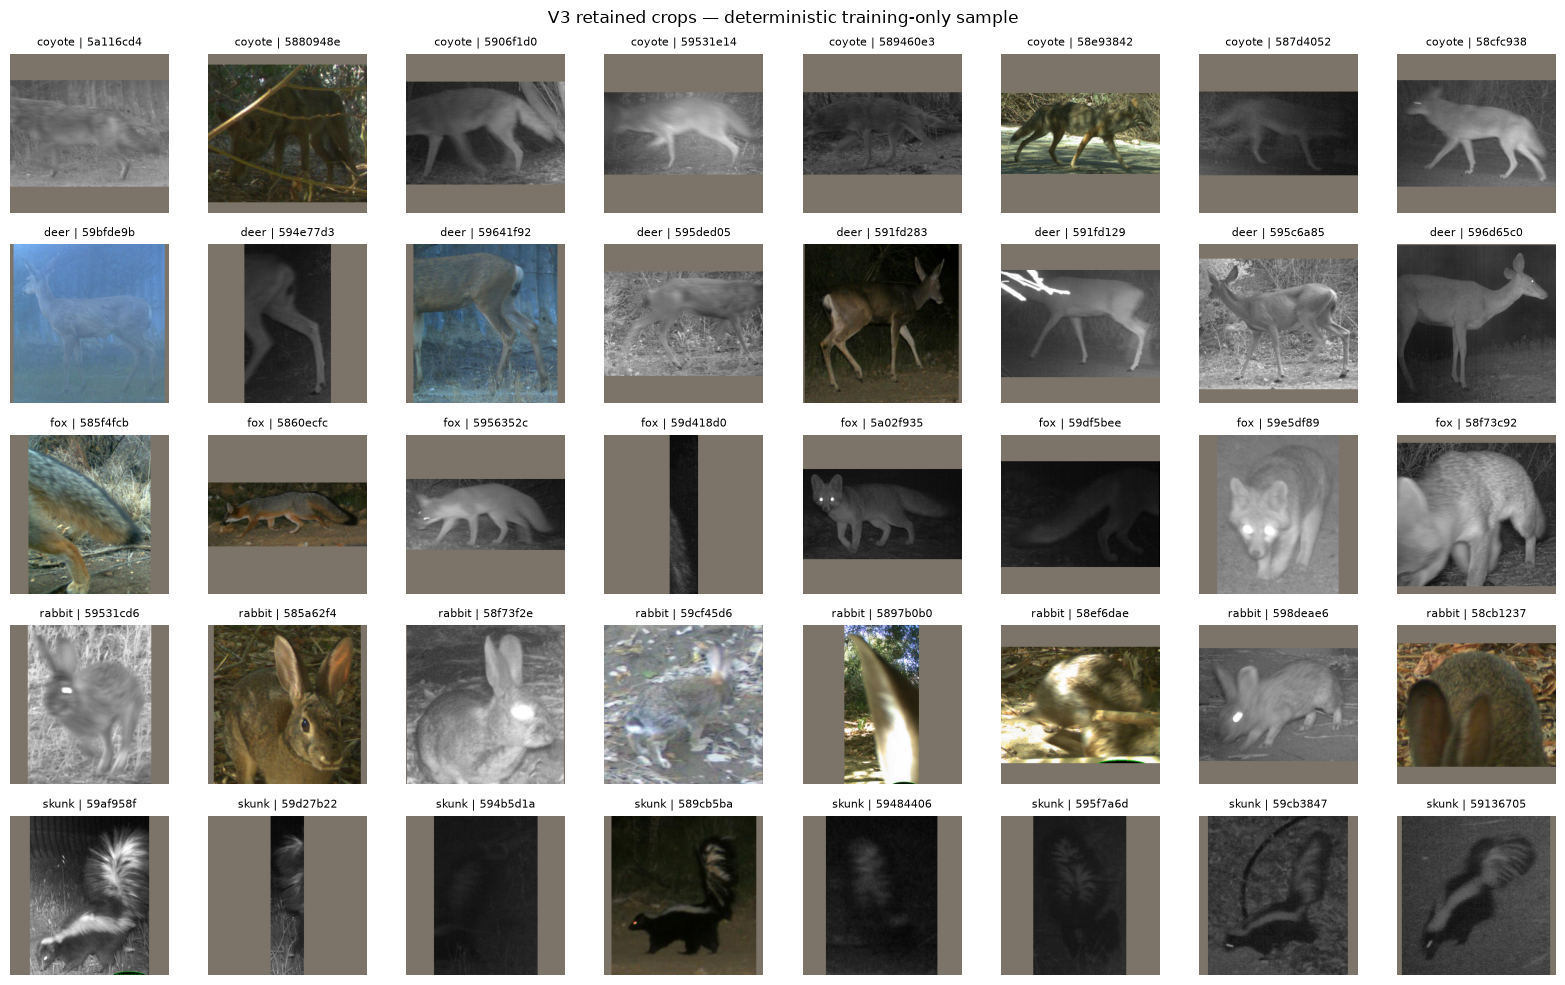

Optional review sheet: /home/fia/Schreibtisch/wildlife_confidence_project_v3/reports/five_categories_detected_only_v3/training_crop_review.csv
This inspection does not silently filter images or certify all labels.


In [4]:
# Training-only visual sample; never show test/calibration/policy images for tuning.
review_parts = []
for name in CLASSES:
    group = verified.loc[verified.split.eq('train') & verified.class_name.eq(name)].copy()
    group['rank'] = group.image_id.map(lambda x: hashlib.sha256(('v3_review|' + x).encode()).hexdigest())
    review_parts.append(group.sort_values('rank').head(8))
review = pd.concat(review_parts, ignore_index=True)
sheet = review[['image_id','class_name','location','split']].copy()
for col in ['animal_visible','crop_matches_label','crop_adequate','reviewer_notes']:
    sheet[col] = ''
if not (REPORT / 'training_crop_review.csv').exists():
    write(REPORT / 'training_crop_review.csv', sheet.to_csv(index=False))
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(16, 10), squeeze=False)
for i, name in enumerate(CLASSES):
    rows = review.loc[review.class_name.eq(name)].reset_index(drop=True)
    for j, ax in enumerate(axes[i]):
        ax.axis('off')
        if j < len(rows):
            row = rows.iloc[j]
            with Image.open(safe(ROOT, row.cache_relative_path)) as image:
                ax.imshow(image)
            ax.set_title(f'{name} | {row.image_id[:8]}', fontsize=8)
fig.suptitle('V3 retained crops — deterministic training-only sample')
fig.tight_layout()
fig.savefig(REPORT / 'training_crop_contact_sheet.png', dpi=130)
plt.show()
plt.close(fig)
print('Optional review sheet:', REPORT / 'training_crop_review.csv')
print('This inspection does not silently filter images or certify all labels.')


## Handoff to training

Once `ready_for_final_training` is true, run Notebook 03 V3 in the same project and Python environment. It rechecks provenance and every cached crop before training. The remaining sequence is independent training of both architectures with seeds 42, 123 and 2026, fresh temperature fitting and policy selection in Notebook 04, followed by the camera robustness audit in Notebook 05.

All reported V3 accuracy, NLL and coverage concern this retained detected-only population. Detector misses and discarded frames are represented by the exclusion counts, not evaluated as species predictions. V3 uses previously examined V2 camera assignments, so its results must retain that limitation.
